100%|██████████| 16.0k/16.0k [00:00<00:00, 17.2MB/s]

Extracting files...
Files: ['/root/.cache/kagglehub/datasets/gokulrajkmv/unemployment-in-india/versions/5/Unemployment in India.csv', '/root/.cache/kagglehub/datasets/gokulrajkmv/unemployment-in-india/versions/5/Unemployment_Rate_upto_11_2020.csv']
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']
Missing values:
 Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


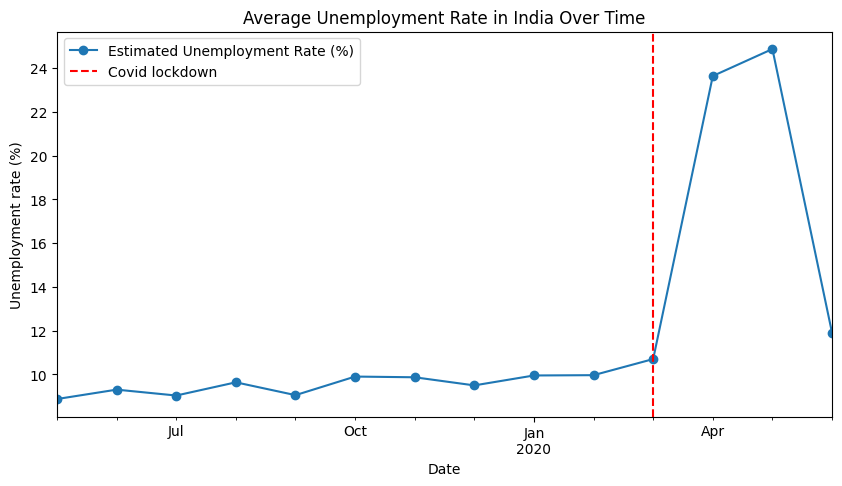

Before Covid: 9.51%
After Covid: 17.77%


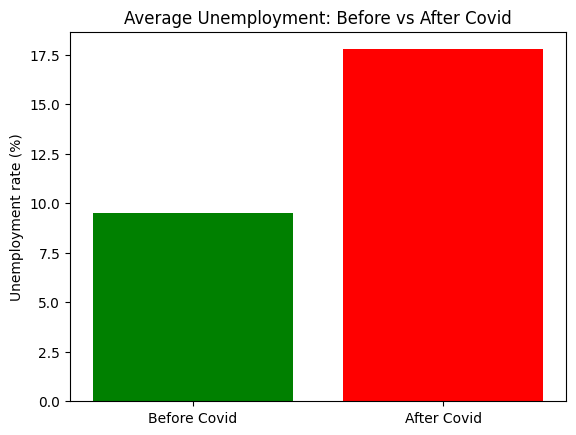

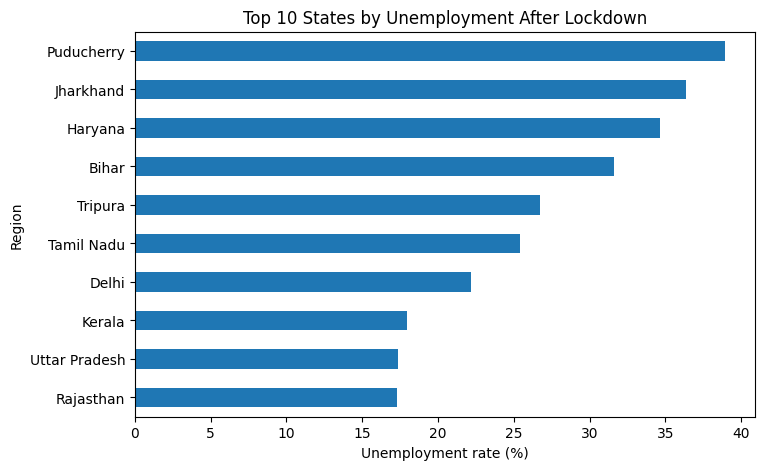

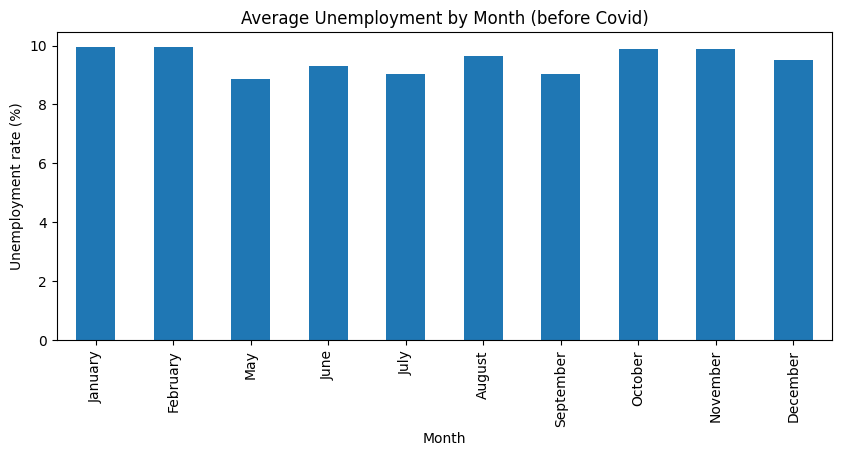

In [2]:
import kagglehub, os, glob
import pandas as pd
import matplotlib.pyplot as plt

path = kagglehub.dataset_download("gokulrajkmv/unemployment-in-india")
files = glob.glob(os.path.join(path, "*.csv"))
print("Files:", files)

main = [f for f in files if "Unemployment in India" in f]
df = pd.read_csv(main[0] if main else files[0])
df.columns = df.columns.str.strip()
print(df.columns.tolist())

rate = [c for c in df.columns if "Unemployment Rate" in c][0]
region = "Region"

print("Missing values:\n", df.isnull().sum())
df = df.dropna()
df["Date"] = pd.to_datetime(df["Date"].str.strip(), dayfirst=True)
df = df.sort_values("Date")

lockdown = pd.Timestamp("2020-03-25")

# Graph 1: trend with the Covid lockdown line
monthly = df.groupby("Date")[rate].mean()
plt.figure(figsize=(10, 5))
monthly.plot(marker="o")
plt.axvline(lockdown, color="red", linestyle="--", label="Covid lockdown")
plt.title("Average Unemployment Rate in India Over Time")
plt.ylabel("Unemployment rate (%)")
plt.legend()
plt.show()

# Before vs after Covid
before = df[df["Date"] < lockdown][rate].mean()
after = df[df["Date"] >= lockdown][rate].mean()
print(f"Before Covid: {before:.2f}%")
print(f"After Covid: {after:.2f}%")

plt.bar(["Before Covid", "After Covid"], [before, after], color=["green", "red"])
plt.title("Average Unemployment: Before vs After Covid")
plt.ylabel("Unemployment rate (%)")
plt.show()

# Graph 2: top 10 states after lockdown
worst = (df[df["Date"] >= lockdown].groupby(region)[rate]
         .mean().sort_values(ascending=False).head(10))
worst.sort_values().plot(kind="barh", figsize=(8, 5),
                         title="Top 10 States by Unemployment After Lockdown")
plt.xlabel("Unemployment rate (%)")
plt.show()

# Graph 3: seasonal pattern (before Covid only)
pre = df[df["Date"] < lockdown].copy()
pre["Month"] = pre["Date"].dt.month_name()
order = ["January","February","March","April","May","June","July",
         "August","September","October","November","December"]
pre.groupby("Month")[rate].mean().reindex(order).dropna().plot(
    kind="bar", figsize=(10, 4), title="Average Unemployment by Month (before Covid)")
plt.ylabel("Unemployment rate (%)")
plt.show()